In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
# The solver, loader, plot and Excel export all live in fast_solver.py so there
# is only one copy to maintain. Re-run this cell after editing that file.
%load_ext autoreload
%autoreload 2

from fast_solver import (
    load_avail_from_csv,
    solve_full_collection_with_fill,
    validate_solution,
    draw_solution,
    export_solution_to_excel,
)


# run this

In [5]:
# ── EDIT THIS CELL ───────────────────────────────────────────────────────────
CSV_PATH       = "Platformless.csv"
EXCEL_OUT      = "Cold.xlsx"
LOG            = False   # per-step progress from the solver module
SOLVER_LOG     = False   # OR-Tools internals; very verbose
MAX_SOLVE_SECS = 15      # ignored when RUN_TO_OPTIMAL = True
RUN_TO_OPTIMAL = True   # True = no time limit, run until both phases prove optimal
WORKERS        = 8
FILL_SIZE      = 2       # size of the fill extras: 2 = 2x2, 3 = 3x3
FILL_LEFTOVERS = True   # True = also paint every remaining free cell as an extra 1x1

# structures = {4: 3,  3: 8, 2: 0,  1: 10+1} # PN
structures = {4: 3,  3: 8, 2: 0,  1: 10} # N

# monsters = {4: 1*3+13, 3: 1*3  , 2: 14*3+1+7+23, 1: 3*3+14} # Plant
monsters = {4: 1*3+10, 3: 3*3  , 2: 12*3+1+7+26, 1: 3*3+14+6} # Cold
# monsters = {4: 1*3+8,  3: 2*3  , 2: 16*3+2,   1: 1*3+70} # Air
# monsters = {4: 1*3+6,  3: 4*3+1, 2: 12*3+2,   1: 2*3+70} # Water
# monsters = {4: 1*3+10, 3: 1*3  , 2: 13*3+2,   1: 4*3+70} # Earth
# monsters = {4: 1*3+6,  3: 2*3  , 2: 14*3+1,   1: 2*3+70} # Haven
# monsters = {4: 0     , 3: 3*3  , 2: 10*3       , 1: 0}      # Crystal
# monsters = {4: 1, 3: 4*3  , 2: 14*3+7+24+7 , 1: 2*3+14+91} # Light



Structures: {1: 10, 2: 0, 3: 8, 4: 3}
Monsters:   {1: 29, 2: 70, 3: 9, 4: 13}
Fill 2x2:   0  (proven maximum)
Free cells: 0
Gradient:   optimal
Time:       4.37s packing + 318.80s layout  (324.11s total)


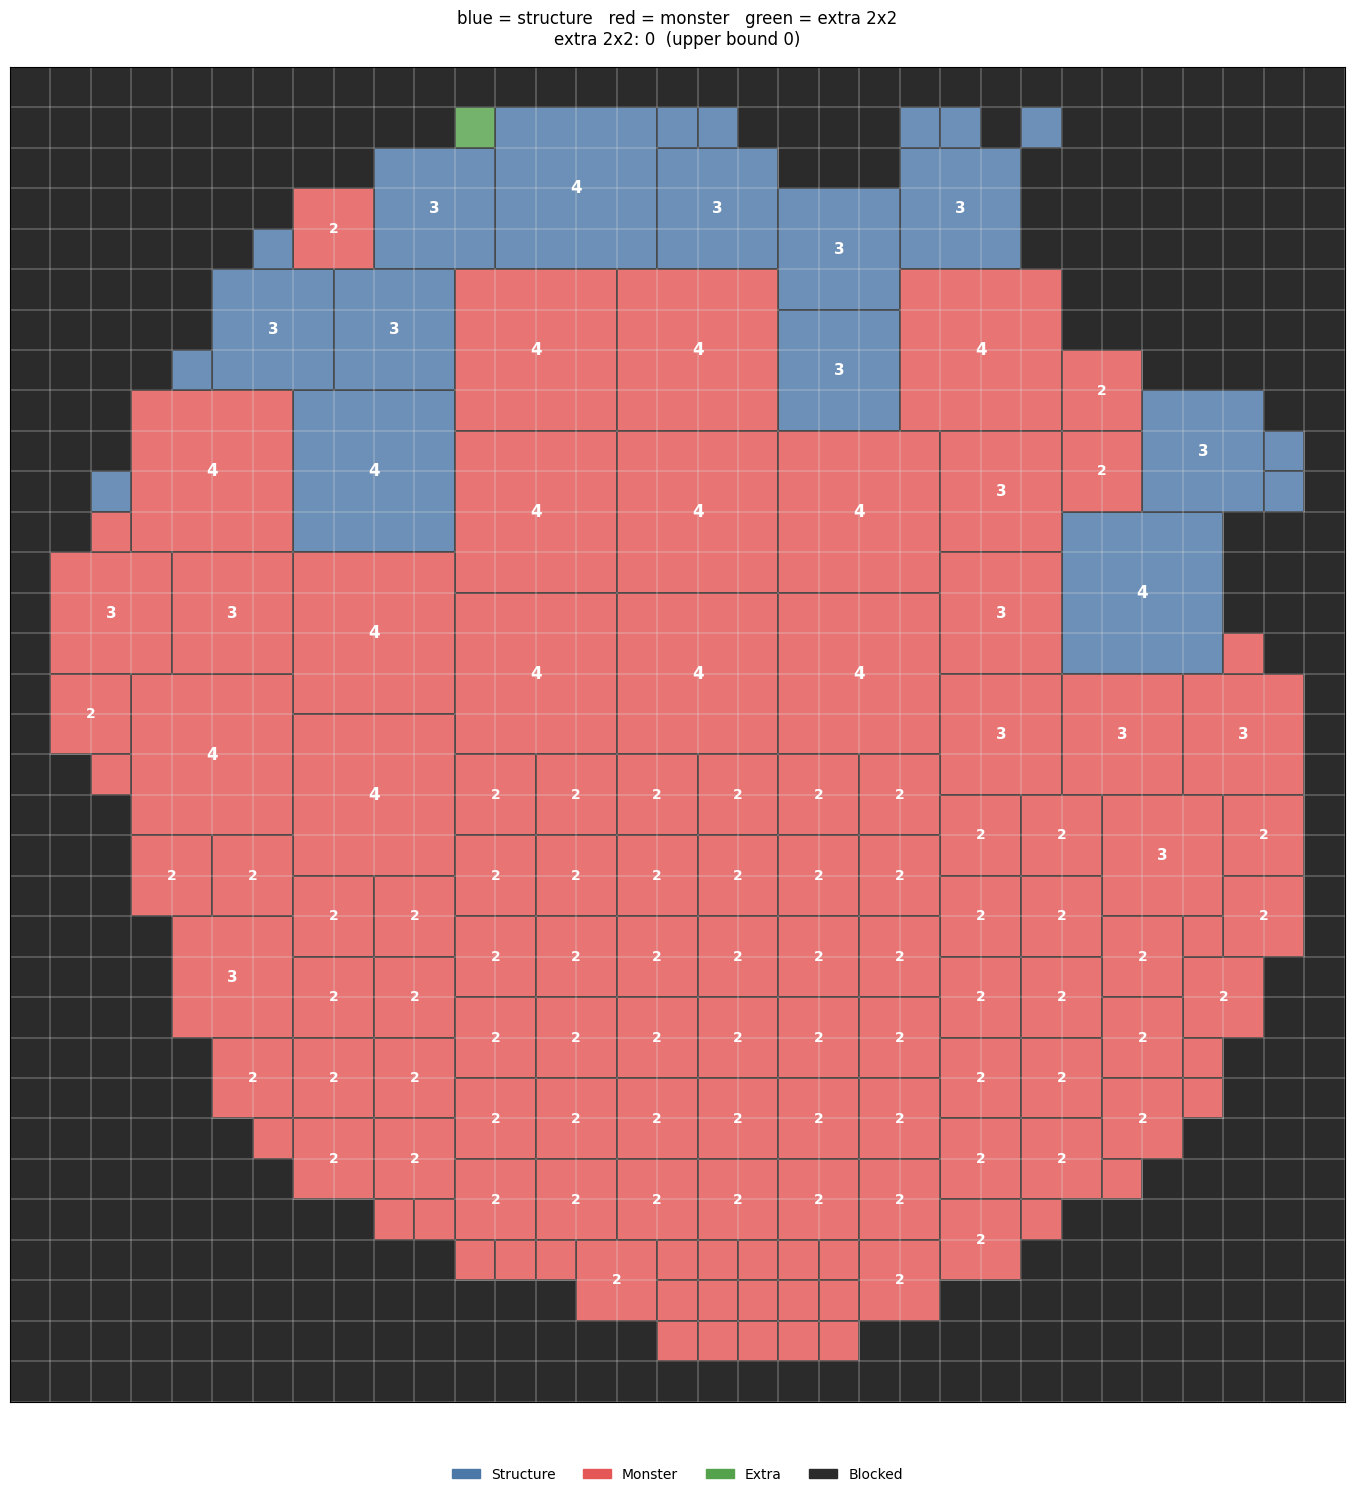

Saved: Cold.xlsx


In [6]:
# ── Run (no editing needed) ──────────────────────────────────────────────────
avail = load_avail_from_csv(CSV_PATH, log=LOG)

sol = solve_full_collection_with_fill(
    avail, structures, monsters,
    log=LOG,
    solver_log=SOLVER_LOG,
    workers=WORKERS,
    max_time_in_seconds=None if RUN_TO_OPTIMAL else MAX_SOLVE_SECS,
    fill_size=FILL_SIZE,
    fill_leftovers=FILL_LEFTOVERS,
)

if not sol["ok"]:
    print("FAILED:", sol.get("reason") or sol.get("status"))
else:
    # Full legality check: exact counts, no overlaps, nothing on a blocked cell.
    problems = validate_solution(avail, sol, structures, monsters)
    if problems:
        raise AssertionError("Invalid layout:\n  " + "\n  ".join(problems))

    fs = sol["fill_size"]
    short = sol["fill_upper_bound"] - sol["fill_count"]
    print(f"Structures: {sol['structures']}")
    print(f"Monsters:   {sol['monsters']}")
    print(f"Fill {fs}x{fs}:   {sol['fill_count']}"
          + ("  (proven maximum)" if sol["fill_optimal"]
             else f"  (up to {short} more may be possible - raise MAX_SOLVE_SECS)"))
    print(f"Free cells: {sol['free_cells']}")
    print(f"Gradient:   {'optimal' if sol['gradient_optimal'] else 'best effort within the time limit'}")
    print(f"Time:       {sol['phase1_seconds']:.2f}s packing + {sol['phase2_seconds']:.2f}s layout"
          f"  ({sol['total_seconds']:.2f}s total)")

    draw_solution(avail, sol)
    print("Saved:", export_solution_to_excel(avail, sol, EXCEL_OUT))


# math

In [4]:
# ── Scratch ──────────────────────────────────────────────────────────────────
werdos  = 408799
wubbox  = 750855
dipsters = 23483
10 * wubbox + 26 * werdos + 6 * dipsters > 11 * wubbox + 23 * werdos + 2 * dipsters


True